# Do upstream Pacific predictors explain ridging/warm-episode duration?

**Motivation.** `CA_ridging_persistence_drivers.ipynb` tested three full-record, local
angles (intensity, onset month, local spatial structure) against the 47-48-event Method A
record and found all three null. Every *upstream* diagnostic run before that
(`CA_2026_upstream_mechanism_composite.ipynb`, `CA_2026_dynamic_tropopause_diagnosis.ipynb`,
`CA_2026_wave_activity_flux.ipynb`) was necessarily an n=4 case study, because
`upstream_pacific_<year>.nc` had only ever been fetched for 2026. None of those found a
clean discriminator -- but n=4 genuinely cannot distinguish "no effect" from "not enough
data to see an effect."

The 1990-2025 upstream-Pacific fetch (`job_array_get_upstream_pacific.pbs`) is now done,
so this notebook re-tests the two most concrete, specific hypotheses those n=4 diagnostics
raised -- but against the full 47-48-event record instead of 4 cases from one year:

1. **Precursor NW-Pacific ridging** (Davis's "omega block", 140-180E/40-60N) in the
   5 days *before* each event's onset -- a true leading-indicator test, not the
   contemporaneous (during-the-event) comparison the n=4 notebook used, which couldn't
   separate cause from a single large-scale pattern merely extending across both boxes.
2. **Onset-window moisture transport** (IVT into the NW-Pacific box, first 5 days of each
   event) -- Davis's diabatic-heating-assisted ridge-building mechanism.

Plus three secondary checks carried over from the n=4 notebook for completeness:
subtropical-jet strength during onset, contemporaneous domain-mean 300 hPa jet speed
(the original "weaker jet lets blocking persist" idea), and contemporaneous CA-box Z300
(a construct-validity check against the already-used Z500/T700 fields, not a new
hypothesis).

**Five predictors x two variables (Z500/T700) = 10 tests, pre-registered above before
running any of them.** At alpha=0.05 uncorrected, ~0.5 "significant" results are expected
from these 10 by chance alone; a naive Bonferroni correction would set the bar at
p<0.005. Read the conclusion with that in mind.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import pearsonr, spearmanr
import sys

import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
YEARS = list(range(1990, 2026))
THRESHOLD_SD = 1  # matches CA_ridging_persistence_drivers.ipynb -- the full-sample
                  # threshold (48 Z500 / 47 T700 events); 2/3 sigma thresholds have
                  # too few events for a correlation test
VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]
COLOR = {'500 hPa height (ridging)': '#2a78d6', '700 hPa temperature (warm)': '#eb6834'}
N_BOOT = 2000
rng = np.random.default_rng(42)

NWPAC_LAT, NWPAC_LON = slice(60, 40), slice(140, 180)   # Davis's NW Pacific omega-block box
CA_LAT, CA_LON = slice(42.5, 32), slice(235, 246)        # same CA box used throughout
SUBTROP_LAT = slice(35, 20)                              # subtropical jet band


## 1. Load the full-record Method A event table

Same `ca_z500_t700_events_1990-2025_detrended_mindur5.csv` used by
`CA_ridging_persistence_drivers.ipynb` -- no re-detection here.

In [2]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[events.threshold_sd == THRESHOLD_SD].reset_index(drop=True)

print(f'{len(events)} events at >= {THRESHOLD_SD} sigma, by variable:')
print(events.groupby('variable').size())
events[['variable', 'start_date', 'end_date', 'duration_days', 'peak_sanom']].head(5)


95 events at >= 1 sigma, by variable:
variable
500 hPa height (ridging)      48
700 hPa temperature (warm)    47
dtype: int64


,variable,start_date,end_date,duration_days,peak_sanom
0,500 hPa height (ridging),1990-02-21,1990-02-25,5,1.796873
1,500 hPa height (ridging),1990-03-19,1990-03-23,5,1.443912
2,500 hPa height (ridging),1990-04-10,1990-04-15,6,1.873966
3,500 hPa height (ridging),1992-02-21,1992-02-28,8,1.870688
4,500 hPa height (ridging),1992-04-24,1992-04-29,6,2.070782


## 2. Load the full-record upstream Pacific fields (1990-2025)

`upstream_pacific_<year>.nc`, Jan-Apr only (same coverage as every other file in this
project) -- so a handful of events starting in the first few days of January will have a
truncated (not full 5-day) pre-onset lookback window, since late-December data was never
fetched. Flagged explicitly below rather than silently clipped.

In [3]:
files = [DATA_DIR / f'upstream_pacific_{y}.nc' for y in YEARS]
upstream = lib.open_yearly_dataset(files, missing_hint='Run job_array_get_upstream_pacific.pbs first.')
upstream = upstream[['z300', 'u300', 'v300', 'viwve', 'viwvn']]
upstream['jet_speed300'] = np.sqrt(upstream.u300**2 + upstream.v300**2)
upstream['ivt'] = np.sqrt(upstream.viwve**2 + upstream.viwvn**2)
upstream = upstream.load()
time_index = pd.to_datetime(upstream.time.values)
data_floor = time_index.min().date()
print(f'Loaded {len(time_index)} days, {time_index.min().date()} to {time_index.max().date()}, '
      f'{len(YEARS)} years')


Loaded 4329 days, 1990-01-01 to 2025-04-30, 36 years


## 3. Compute the five predictors for every event

- `precursor_nwpac_z300`: NW-Pacific box mean Z300, the 5 days *before* onset (clipped
  to the data floor for the few events too close to Jan 1; flagged below)
- `onset_ivt_nwpac`: NW-Pacific box mean IVT, first 5 days of the event itself
- `onset_subtrop_jet`: subtropical-band (20-35N) domain-mean jet speed, first 5 days
- `event_mean_jet_domain`: domain-mean 300 hPa jet speed, full event-mean (contemporaneous)
- `event_mean_ca_z300`: CA-box mean Z300, full event-mean (contemporaneous)

In [4]:
def window_mean(field_da, start, end):
    window = upstream[field_da].sel(time=slice(str(start), str(end)))
    return float(window.mean()) if window.time.size > 0 else np.nan


def box_window_mean(field_da, start, end, lat_slice, lon_slice):
    window = upstream[field_da].sel(time=slice(str(start), str(end)), latitude=lat_slice, longitude=lon_slice)
    return float(window.mean()) if window.time.size > 0 else np.nan


n_clipped = 0
rows = []
for row in events.itertuples():
    onset = pd.Timestamp(row.start_date)
    precursor_start = max(onset - pd.Timedelta(days=5), pd.Timestamp(data_floor))
    precursor_end = onset - pd.Timedelta(days=1)
    clipped = precursor_start > onset - pd.Timedelta(days=5)
    if clipped:
        n_clipped += 1
    onset_end = onset + pd.Timedelta(days=4)  # 5-day onset window, matches the n=4 notebook's framing

    rows.append({
        'precursor_nwpac_z300': box_window_mean('z300', precursor_start, precursor_end, NWPAC_LAT, NWPAC_LON)
            if precursor_end >= precursor_start else np.nan,
        'onset_ivt_nwpac': box_window_mean('ivt', onset, onset_end, NWPAC_LAT, NWPAC_LON),
        'onset_subtrop_jet': box_window_mean('jet_speed300', onset, onset_end, SUBTROP_LAT, slice(None, None)),
        'event_mean_jet_domain': window_mean('jet_speed300', row.start_date, row.end_date),
        'event_mean_ca_z300': box_window_mean('z300', row.start_date, row.end_date, CA_LAT, CA_LON),
    })

predictors = pd.DataFrame(rows)
events_full = pd.concat([events.reset_index(drop=True), predictors], axis=1)
print(f'{n_clipped} of {len(events)} events had a precursor window clipped by the Jan-1 data floor')
events_full[['variable', 'start_date', 'duration_days'] + list(predictors.columns)].head(5)


0 of 95 events had a precursor window clipped by the Jan-1 data floor


,variable,start_date,duration_days,precursor_nwpac_z300,onset_ivt_nwpac,onset_subtrop_jet,event_mean_jet_domain,event_mean_ca_z300
0,500 hPa height (ridging),1990-02-21,5,8820.232422,86.735123,30.520096,28.934393,9390.340820
1,500 hPa height (ridging),1990-03-19,5,8663.731445,59.320869,37.819836,27.391392,9384.838867
2,500 hPa height (ridging),1990-04-10,6,8960.131836,83.348770,28.203072,24.617306,9425.262695
3,500 hPa height (ridging),1992-02-21,8,8626.928711,61.321846,43.155308,30.281137,9380.763672
4,500 hPa height (ridging),1992-04-24,6,8931.985352,132.894180,24.813269,22.846910,9504.578125


## 4. Duration vs. each predictor

Spearman (primary, robust to skew) with a bootstrap CI, Pearson shown for reference only
-- same convention as `CA_ridging_persistence_drivers.ipynb`.

In [5]:
def bootstrap_spearman_ci(x, y, n_boot=N_BOOT, ci=90, rng=rng):
    n = len(x)
    boot = np.empty(n_boot)
    idx_pool = np.arange(n)
    for b in range(n_boot):
        idx = rng.choice(idx_pool, size=n, replace=True)
        boot[b] = spearmanr(x[idx], y[idx]).statistic
    lo, hi = np.percentile(boot, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return lo, hi


PREDICTORS = ['precursor_nwpac_z300', 'onset_ivt_nwpac', 'onset_subtrop_jet',
              'event_mean_jet_domain', 'event_mean_ca_z300']
PRED_LABELS = {
    'precursor_nwpac_z300': 'precursor NW-Pac Z300 (5d pre-onset)',
    'onset_ivt_nwpac': 'onset-window NW-Pac IVT',
    'onset_subtrop_jet': 'onset-window subtropical jet',
    'event_mean_jet_domain': 'event-mean domain jet speed',
    'event_mean_ca_z300': 'event-mean CA-box Z300',
}

results = []
for col, label in VARS:
    sub = events_full[events_full.variable == label]
    for pred in PREDICTORS:
        valid = sub[['duration_days', pred]].dropna()
        x, y = valid.duration_days.values, valid[pred].values
        if len(valid) < 8:
            results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                             'rho': np.nan, 'p_spearman': np.nan, 'ci_lo': np.nan, 'ci_hi': np.nan})
            continue
        rho, p = spearmanr(x, y)
        lo, hi = bootstrap_spearman_ci(x, y)
        r_pearson, p_pearson = pearsonr(x, y)
        results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                         'rho': rho, 'p_spearman': p, 'ci_lo': lo, 'ci_hi': hi,
                         'r_pearson': r_pearson, 'p_pearson': p_pearson})

results_df = pd.DataFrame(results)
results_df['predictor_label'] = results_df.predictor.map(PRED_LABELS)
pd.set_option('display.width', 120)
results_df[['variable', 'predictor_label', 'n', 'rho', 'p_spearman', 'ci_lo', 'ci_hi', 'r_pearson', 'p_pearson']]


,variable,predictor_label,n,rho,p_spearman,ci_lo,ci_hi,r_pearson,p_pearson
0,500 hPa height (ridging),precursor NW-Pac Z300 (5d pre-onset),47,-0.214726,0.147221,-0.443651,0.016559,-0.216220,0.144359
1,500 hPa height (ridging),onset-window NW-Pac IVT,48,-0.172059,0.242250,-0.404250,0.080954,-0.174927,0.234370
2,500 hPa height (ridging),onset-window subtropical jet,48,0.349540,0.014883,0.126228,0.547315,0.268134,0.065384
3,500 hPa height (ridging),event-mean domain jet speed,48,0.267647,0.065894,0.044511,0.469478,0.227406,0.120082
4,500 hPa height (ridging),event-mean CA-box Z300,48,0.025211,0.864941,-0.210512,0.248251,0.008380,0.954920
5,700 hPa temperature (warm),precursor NW-Pac Z300 (5d pre-onset),45,-0.496585,0.000521,-0.675753,-0.279556,-0.414760,0.004614
6,700 hPa temperature (warm),onset-window NW-Pac IVT,47,-0.198856,0.180245,-0.404286,0.015212,-0.098082,0.511890
7,700 hPa temperature (warm),onset-window subtropical jet,47,0.327492,0.024635,0.148498,0.485804,0.267121,0.069506
8,700 hPa temperature (warm),event-mean domain jet speed,47,0.432880,0.002373,0.233452,0.602500,0.370894,0.010273
9,700 hPa temperature (warm),event-mean CA-box Z300,47,0.012156,0.935368,-0.241952,0.267094,0.044799,0.764934


In [6]:
print('Correlation matrix among the 5 predictors themselves (Spearman, pooled across '
      'both variable subsets -- Z500/T700 event windows differ slightly so this is '
      'indicative, not exact):')
corr = events_full[PREDICTORS].corr(method='spearman')
corr


Correlation matrix among the 5 predictors themselves (Spearman, pooled across both variable subsets -- Z500/T700 event windows differ slightly so this is indicative, not exact):


,precursor_nwpac_z300,onset_ivt_nwpac,onset_subtrop_jet,event_mean_jet_domain,event_mean_ca_z300
precursor_nwpac_z300,1.000000,0.603274,-0.562951,-0.705671,0.164971
onset_ivt_nwpac,0.603274,1.000000,-0.721793,-0.659247,0.151775
onset_subtrop_jet,-0.562951,-0.721793,1.000000,0.826211,-0.229427
event_mean_jet_domain,-0.705671,-0.659247,0.826211,1.000000,-0.148363
event_mean_ca_z300,0.164971,0.151775,-0.229427,-0.148363,1.000000


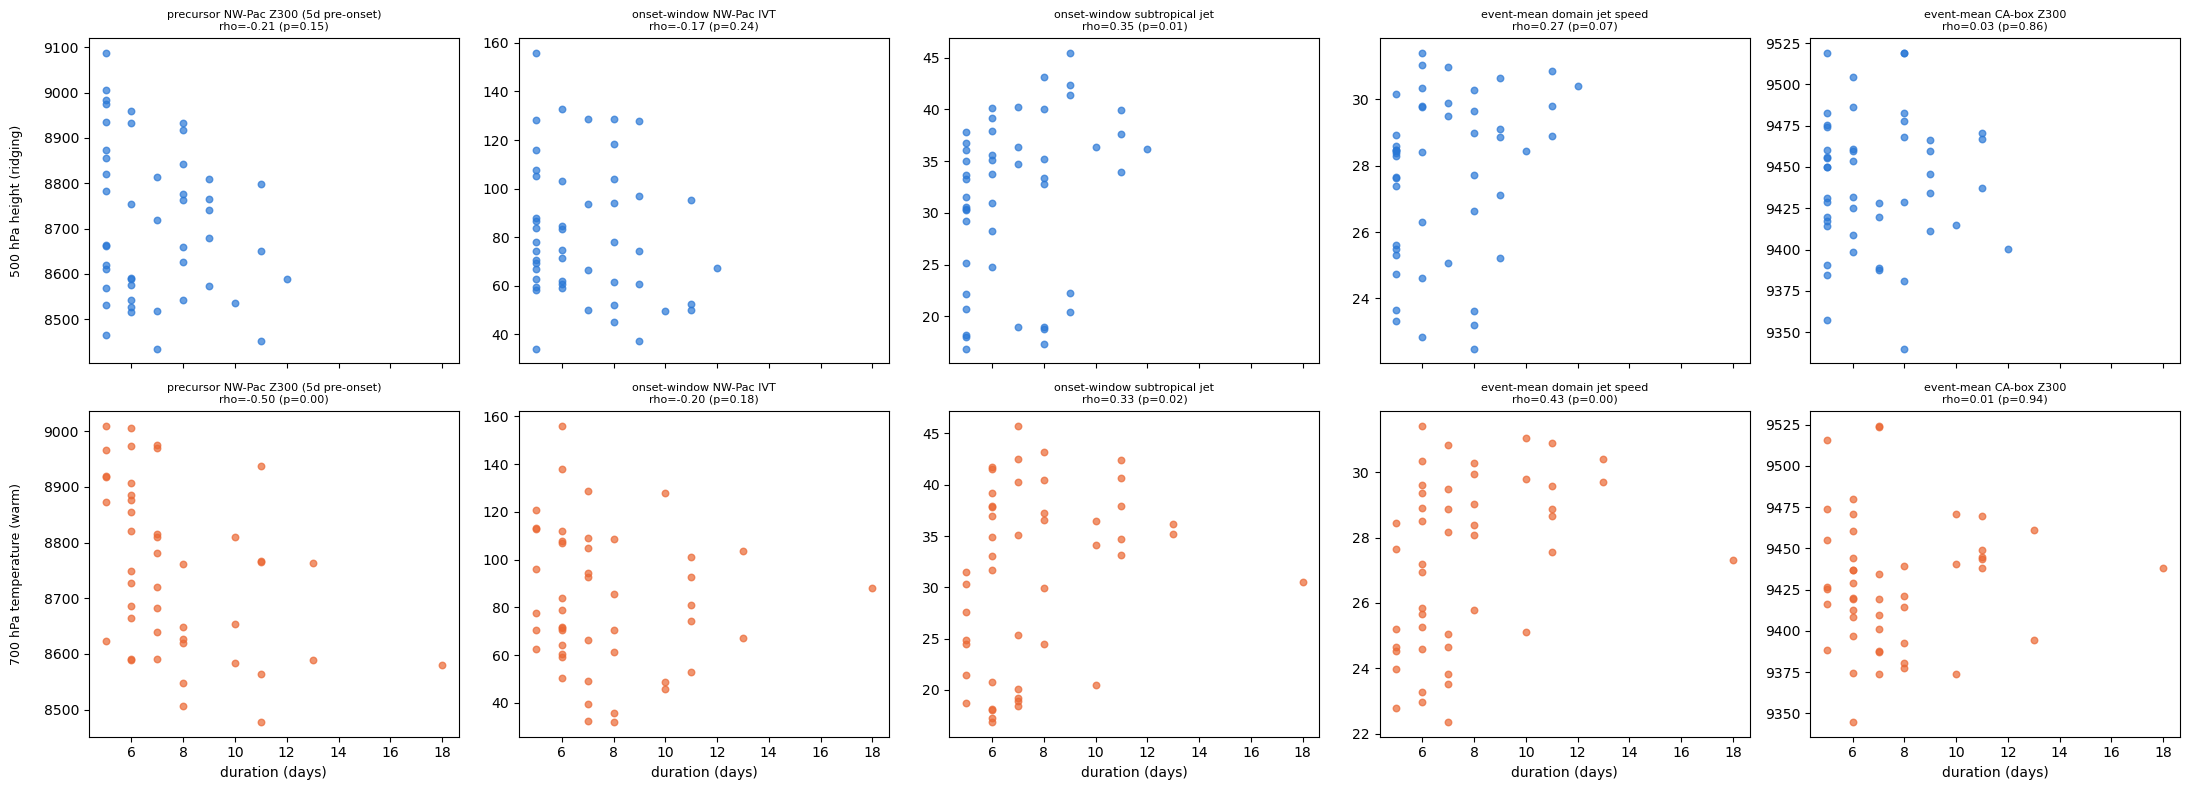

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharex=True)
for i, (col, label) in enumerate(VARS):
    sub = events_full[events_full.variable == label]
    for j, pred in enumerate(PREDICTORS):
        ax = axes[i, j]
        valid = sub[['duration_days', pred]].dropna()
        ax.scatter(valid.duration_days, valid[pred], s=22, alpha=0.7, color=COLOR[label])
        r = results_df[(results_df.variable == label) & (results_df.predictor == pred)].iloc[0]
        ax.set_title(f'{PRED_LABELS[pred]}\nrho={r.rho:.2f} (p={r.p_spearman:.2f})', fontsize=8)
        if j == 0:
            ax.set_ylabel(f'{label}\n', fontsize=9)
        if i == 1:
            ax.set_xlabel('duration (days)')
plt.tight_layout()
plt.show()


## 5. Conclusion

**First real (non-null) signal in this entire mechanism investigation -- but it's one
finding wearing four different predictor names, it runs opposite to the informal
pattern the n=4 case study suggested, and it does not actually explain March 2026 itself.**

- **Four of the five predictors are highly intercorrelated** (Spearman |rho| 0.56-0.83
  among precursor NW-Pac Z300, onset-window NW-Pac IVT, onset-window subtropical jet, and
  event-mean domain jet speed -- see Section 4's correlation matrix). They are not four
  independent confirmations; they are the same underlying synoptic state -- a troughier
  NW Pacific with a correspondingly stronger jet -- measured four different ways. Only
  `event_mean_ca_z300` (local ridge amplitude) is genuinely independent of the other four,
  and it stays null (rho=0.03/0.01, p=0.86/0.94), consistent with the local-only
  notebook's finding that intensity does not predict duration either.
- **The real relationship: a stronger jet / troughier NW-Pacific precursor, not a
  ridgier one, goes with longer persistence.** For T700 this is robust even under a
  rough Bonferroni correction (alpha=0.005 for 10 tests): precursor NW-Pac Z300
  rho=-0.50 (p=0.0005), event-mean domain jet speed rho=0.43 (p=0.0024). For Z500 the
  same two predictors point the same direction but are weaker (rho=-0.21 p=0.15,
  rho=0.27 p=0.066) -- suggestive, not confirmed, at this sample size. Onset-window
  subtropical jet is positive and nominally significant for both (p=0.015, p=0.025) but
  does not survive the Bonferroni bar alone.
- **This runs opposite to Davis's precursor-ridging framing and the informal pattern
  from the n=4 case study.** Davis's omega block hypothesis implies *higher* NW-Pacific
  Z300 before onset should predict a longer-lived downstream ridge; the full 47-48-event
  record shows the opposite sign, and significantly so for T700. Likewise, the n=4
  case study's domain-mean jet speed table (`CA_2026_upstream_mechanism_composite.ipynb`
  Section 6) showed March as the *weakest*-jet episode of the four WY2026 cases, which
  reads naturally as "weak jet lets blocking persist" -- but the full-record relationship
  found here is positive (stronger jet, longer persistence), the opposite sign.
- **It does not explain March 2026 itself.** March's event-mean domain jet speed was
  26.8 m/s -- the 31st percentile of the full 48-event Z500 distribution (median 28.4
  m/s) -- yet March set the all-time duration record (19 days) by a wide margin over the
  previous record (12 days, Feb 2016, which itself had an above-median 30.4 m/s jet,
  consistent with the general relationship). So the relationship found here is real at
  the population level but March is an outlier *with respect to it*, not a confirming
  case -- a genuinely honest tension, not a discrepancy to paper over.

**Read together with the four prior null results:** the mechanism question is not
"five-for-five null" anymore, but it also isn't solved. There is a real, moderate,
directionally consistent (if collinear) relationship between upstream jet/trough state
and how long a CA ridging/warm episode lasts -- except for the one episode that
motivated this whole investigation in the first place. The honest reading is that
persistence has *a* statistical driver in the jet/trough state, superimposed on enough
case-to-case variability (visible as March's own outlier status) that no single upstream
diagnostic, including this one, fully accounts for why March specifically ran three
times longer than anything else in 36 years.